# E6: B+ tree cost vs order

Question: what B+ tree order is best, and does the answer depend on build, point lookup, or range search?
Data: `E6_bplus_order` rows from `results/timings.csv`, one machine, one code version. Nine orders, seven track-ID sizes, and 5 replicates.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path("..") if (Path("..") / "results/timings.csv").exists() else Path(".")
df = pd.read_csv(root / "results/timings.csv")
e6 = df[df["experiment"] == "E6_bplus_order"]

# Control the comparison: one machine, one version, one complete session.
machine = "oscar-omen"
version = "584f39d"
e6 = e6[(e6["machine_id"] == machine) & (e6["code_version"] == version)].copy()
if e6.empty:
    raise ValueError(f"No E6 measurements for {machine}, {version}")
session = e6.groupby("session_id")["timestamp_utc"].max().idxmax()
e6 = e6[e6["session_id"] == session].copy()
e6["order"] = e6["index_param"].str.extract(r"order=(\d+)", expand=False).astype(int)
e6["us_per_op"] = e6["total_ns"] / e6["n_ops"] / 1000
e6["build_ms"] = e6["total_ns"] / 1_000_000
for c in ["comparisons", "nodes_visited"]:
    e6[c + "_per_op"] = e6[c] / e6["n_ops"]

orders = [3, 4, 8, 16, 32, 64, 128, 256, 512]
focus_n = 114000
counts = e6.groupby(["operation", "key_column", "n_keys", "order"])["rep"].nunique()
assert len(counts) == 198 and counts.min() >= 5, "E6 needs all 198 configurations with 5 replicates."
assert set(e6["order"]) == set(orders)
assert not e6.duplicated(["operation", "key_column", "n_keys", "order", "rep"]).any()
figures = root / "report/figures/e6"
tables = root / "report/tables/e6"
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
print(machine, version, session, len(e6), "rows")
e6.groupby(["operation", "key_column"]).size().rename("rows").to_frame()

oscar-omen bc253d0-dirty 9f5220ec7660 990 rows


,,rows
operation,key_column,
build,track_id,315
point_hit,track_id,315
point_miss,track_id,315
range,tempo,45


## Median and IQR across the 5 replicates

Builds use total milliseconds. Hits and misses use 500-query batches on track IDs; ranges use 200 queries on all tempo pairs at 1% distinct-key selectivity. Query times are µs per operation.

In [2]:
parts = []
for operation in ["build", "point_hit", "point_miss", "range"]:
    metric = "build_ms" if operation == "build" else "us_per_op"
    s = (e6[e6["operation"] == operation]
         .groupby(["operation", "key_column", "n_keys", "order"])[metric]
         .quantile([.25, .5, .75]).unstack()
         .rename(columns={.25: "q25", .5: "median", .75: "q75"}).reset_index())
    s["unit"] = "ms per build" if operation == "build" else "µs per query"
    parts.append(s)
summary = pd.concat(parts, ignore_index=True)
summary.to_csv(tables / "E6_timing_summary.csv", index=False)
summary[summary["n_keys"] == focus_n][
    ["operation", "order", "median", "q25", "q75", "unit"]
].round(3)

,operation,order,median,q25,q75,unit
54,build,3,1451.240,1440.025,1613.653,ms per build
55,build,4,1116.248,1105.716,1146.953,ms per build
56,build,8,763.702,752.002,823.755,ms per build
57,build,16,637.404,571.158,751.341,ms per build
58,build,32,497.946,493.640,501.459,ms per build
59,build,64,445.016,443.038,451.360,ms per build
60,build,128,458.625,451.668,461.389,ms per build
61,build,256,424.486,417.100,425.466,ms per build
62,build,512,425.424,424.479,436.005,ms per build
117,point_hit,3,11.301,10.637,12.360,µs per query


## Cost vs order at 114,000 pairs

Line = median, band = IQR. Builds/hits/misses use track IDs; ranges use tempos. Compare orders within each operation.

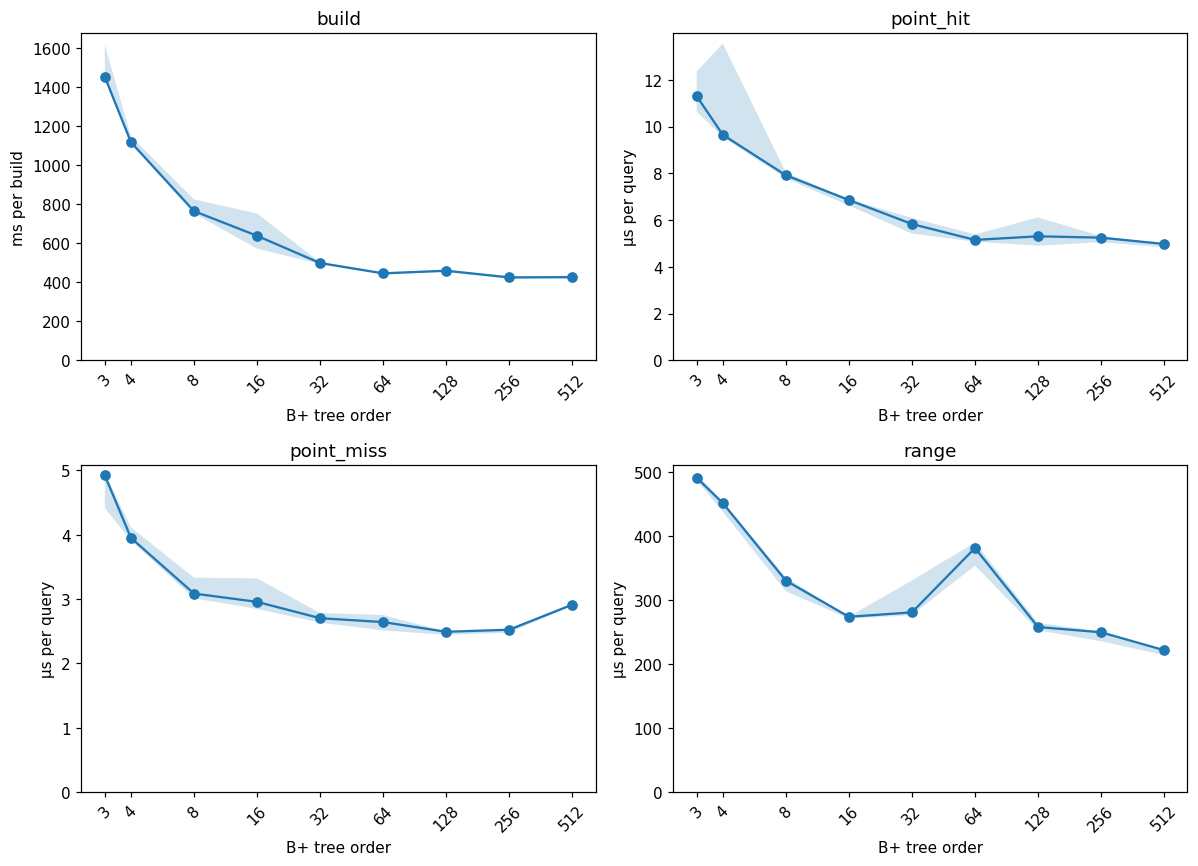

In [3]:
operations = ["build", "point_hit", "point_miss", "range"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, operation in zip(axes.flat, operations):
    s = summary[(summary["operation"] == operation) & (summary["n_keys"] == focus_n)].sort_values("order")
    ax.plot(s["order"], s["median"], marker="o")
    ax.fill_between(s["order"], s["q25"], s["q75"], alpha=.2)
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders, [str(x) for x in orders], rotation=45)
    ax.set(xlabel="B+ tree order", title=operation,
           ylabel="ms per build" if operation == "build" else "µs per query", ylim=(0, None))
plt.tight_layout()
fig.savefig(figures / "E6_cost_vs_order.png", dpi=180, bbox_inches="tight")
plt.show()

## Cost vs n at each order

Track-ID builds, hits and misses use sizes 1,000, 2,000, 5,000, 10,000, 20,000, 50,000 and 114,000. Both axes are logarithmic. Ranges have one size, so they are not included here.

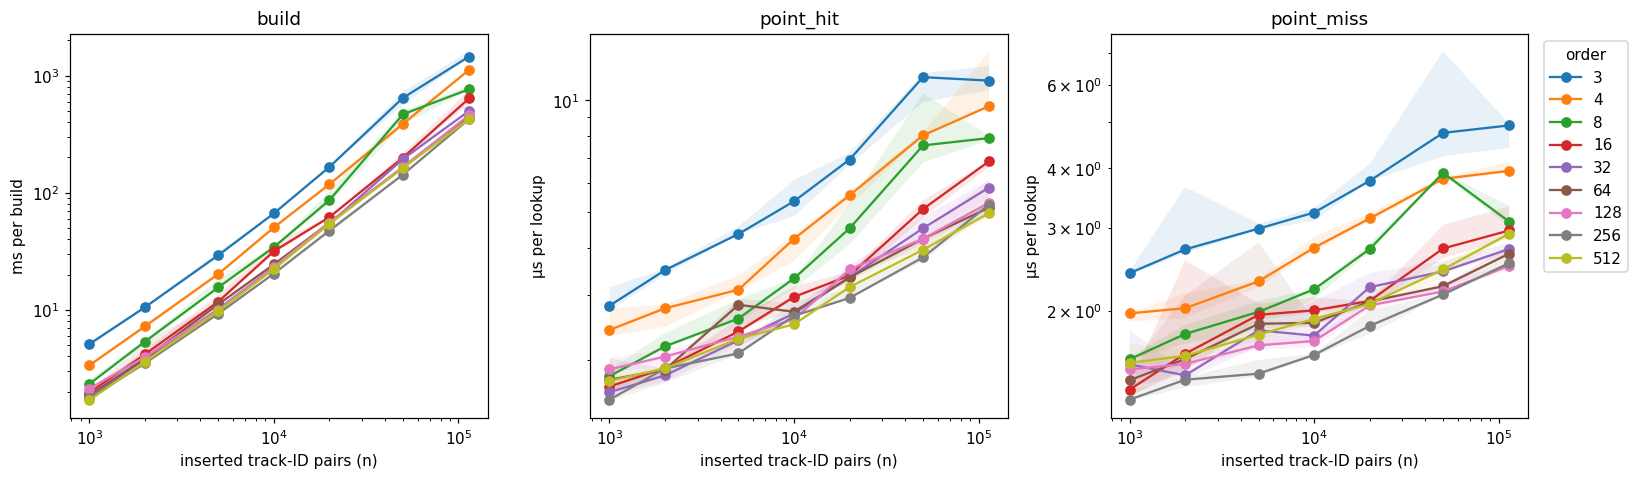

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, operation in zip(axes, ["build", "point_hit", "point_miss"]):
    for order in orders:
        s = summary[(summary["operation"] == operation) & (summary["order"] == order)].sort_values("n_keys")
        ax.plot(s["n_keys"], s["median"], marker="o", label=str(order))
        ax.fill_between(s["n_keys"], s["q25"], s["q75"], alpha=.1)
    ax.set(xscale="log", yscale="log", xlabel="inserted track-ID pairs (n)", title=operation,
           ylabel="ms per build" if operation == "build" else "µs per lookup")
axes[-1].legend(title="order", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(figures / "E6_cost_vs_size.png", dpi=180, bbox_inches="tight")
plt.show()

## Height and splits

A larger order should reduce tree height and splits. Splits belong to build rows: the counters are reset before queries. Track-ID and tempo trees can have different heights because their distinct-key counts differ.

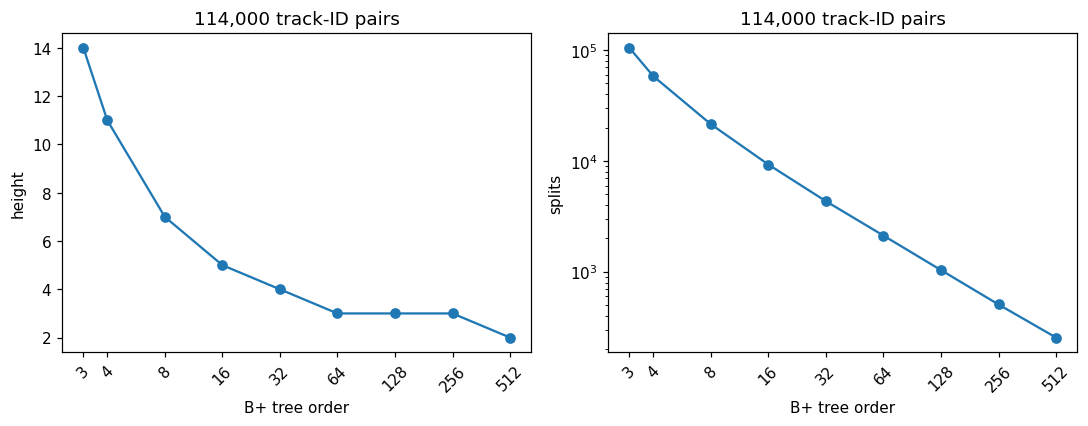

,n_keys,order,height,splits
54,114000,3,14.0,104634.0
55,114000,4,11.0,58119.0
56,114000,8,7.0,21434.0
57,114000,16,5.0,9272.0
58,114000,32,4.0,4330.0
59,114000,64,3.0,2120.0
60,114000,128,3.0,1035.0
61,114000,256,3.0,507.0
62,114000,512,2.0,255.0


In [5]:
shape = (e6[e6["operation"] == "build"]
         .groupby(["n_keys", "order"])[["height", "splits"]].median().reset_index())
shape.to_csv(tables / "E6_height_splits.csv", index=False)
s = shape[shape["n_keys"] == focus_n].sort_values("order")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["height", "splits"]):
    ax.plot(s["order"], s[metric], marker="o")
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders, [str(x) for x in orders], rotation=45)
    ax.set(xlabel="B+ tree order", ylabel=metric, title=f"{focus_n:,} track-ID pairs")
    if metric == "splits":
        ax.set_yscale("log")
plt.tight_layout()
fig.savefig(figures / "E6_height_splits.png", dpi=180, bbox_inches="tight")
plt.show()
s

## Counters per query

Fewer nodes can reduce pointer traversal, but comparisons inside wider nodes still cost time. The counters do not measure every list shift, allocation or result-copy operation.

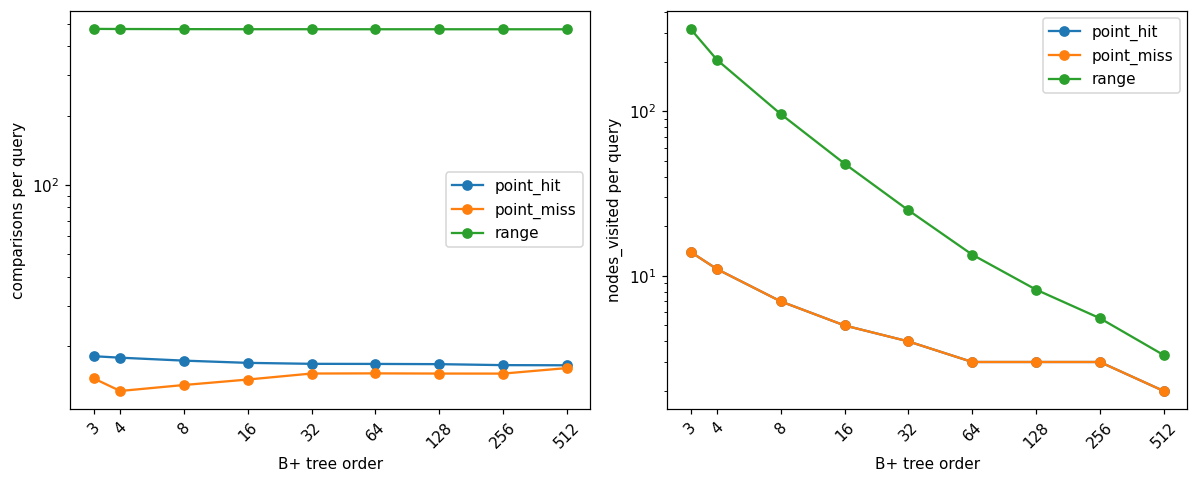

comparisons_per_op  nodes_visited_per_op
operation  order                                          
point_hit  3                  18.098                14.000
           4                  17.832                11.000
           8                  17.314                 7.000
           16                 16.932                 5.000
           32                 16.770                 4.000
           64                 16.754                 3.000
           128                16.716                 3.000
           256                16.554                 3.000
           512                16.530                 2.000
point_miss 3                  14.498                14.000
           4                  12.788                11.000
           8                  13.574                 7.000
           16                 14.336                 5.000
           32                 15.222                 4.000
           64                 15.246                 3.000
           128                15.218                 3.000
           256                15.210                 3.000
           512                16.074                 2.000
range      3                 475.455               316.995
           4                 474.900               205.415
           8                 474.290                96.185
           16                473.925                48.055
           32                473.885                25.050
           64                473.720                13.465
           128               473.720                 8.255
           256               473.635                 5.535
           512               473.585                 3.305

In [6]:
queries = e6[(e6["operation"] != "build") & (e6["n_keys"] == focus_n)]
counters = queries.groupby(["operation", "order"])[
    ["comparisons_per_op", "nodes_visited_per_op"]
].median()
counters.to_csv(tables / "E6_query_counters.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ["comparisons_per_op", "nodes_visited_per_op"]):
    for operation in ["point_hit", "point_miss", "range"]:
        s = counters.loc[operation]
        ax.plot(s.index, s[metric], marker="o", label=operation)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(orders, [str(x) for x in orders], rotation=45)
    ax.set(xlabel="B+ tree order", ylabel=metric.replace("_per_op", " per query"))
    ax.legend()
plt.tight_layout()
fig.savefig(figures / "E6_query_counters.png", dpi=180, bbox_inches="tight")
plt.show()
counters.round(3)

## Best order for each operation and size

Rank by median and compare the best order with the runner-up and default order 32. Overlapping IQRs are not evidence of a clear timing difference.

In [7]:
best_rows = []
for (operation, key_column, n), group in summary.groupby(["operation", "key_column", "n_keys"]):
    ranked = group.sort_values("median")
    best, runner = ranked.iloc[0], ranked.iloc[1]
    default = group[group["order"] == 32].iloc[0]
    best_rows.append({
        "operation": operation, "key_column": key_column, "n_keys": n,
        "best order": int(best["order"]), "median": best["median"], "unit": best["unit"],
        "runner-up": int(runner["order"]),
        "IQRs overlap": max(best["q25"], runner["q25"]) <= min(best["q75"], runner["q75"]),
        "default 32 / best": default["median"] / best["median"],
    })
best_orders = pd.DataFrame(best_rows)
best_orders.to_csv(tables / "E6_best_orders.csv", index=False)
best_orders[best_orders["n_keys"] == focus_n].round(3)

,operation,key_column,n_keys,best order,median,unit,runner-up,IQRs overlap,default 32 / best
6,build,track_id,114000,256,424.486,ms per build,512,True,1.173
13,point_hit,track_id,114000,512,4.978,µs per query,64,False,1.171
20,point_miss,track_id,114000,128,2.492,µs per query,256,True,1.085
21,range,tempo,114000,512,221.563,µs per query,256,False,1.266


## Fitted slopes vs expected growth

Fit log10(cost) = a + k log10(n) to per-size medians at each fixed order. The interval resamples the replicates within each size, refits and repeats 1,000 times. Total linear build cost corresponds to a slope near 1; logarithmic lookup growth produces a small positive slope over this range.

In [8]:
rng = np.random.default_rng(4300)

def slope(ns, costs):
    return np.polyfit(np.log10(ns), np.log10(costs), 1)[0]

slope_rows = []
for (operation, order), group in e6[e6["operation"] != "range"].groupby(["operation", "order"]):
    metric = "build_ms" if operation == "build" else "us_per_op"
    by_n = {n: part[metric].to_numpy() for n, part in group.groupby("n_keys")}
    ns = sorted(by_n)
    k = slope(ns, [np.median(by_n[n]) for n in ns])
    boot = [slope(ns, [np.median(rng.choice(by_n[n], len(by_n[n]), replace=True)) for n in ns])
            for _ in range(1000)]
    lo, hi = np.quantile(boot, [.025, .975])
    slope_rows.append({"operation": operation, "order": order, "slope": k, "ci_lo": lo, "ci_hi": hi})
slopes = pd.DataFrame(slope_rows)
slopes.to_csv(tables / "E6_slopes.csv", index=False)
slopes.round(3)

,operation,order,slope,ci_lo,ci_hi
0,build,3,1.223,1.184,1.260
1,build,4,1.232,1.205,1.249
2,build,8,1.273,1.219,1.299
3,build,16,1.215,1.179,1.268
4,build,32,1.202,1.175,1.221
5,build,64,1.159,1.107,1.209
6,build,128,1.150,1.092,1.160
7,build,256,1.159,1.117,1.173
8,build,512,1.177,1.163,1.193
9,point_hit,3,0.319,0.273,0.342


## Observations

- **Build.** At 114,000 track-ID pairs, order 256 has the lowest median build time, 424.49 ms. Order 512 is almost the same at 425.42 ms, and their IQRs overlap. These measurements do not establish a clear difference between them.
- **Point hits.** Order 512 has the lowest median at 4.98 µs per hit. Order 64 is next at 5.15 µs. The lower height helps explain why large orders outperform order 3, which costs 11.30 µs per hit.
- **Point misses.** Order 128 has the lowest median at 2.49 µs; order 256 is close at 2.53 µs, with overlapping IQRs. Order 512 is slower at 2.91 µs even though its tree is shorter. Fewer nodes do not guarantee the lowest wall-clock time.
- **Ranges.** At 1% tempo selectivity, order 512 has the lowest median at 221.56 µs per range, followed by order 256 at 249.49 µs. The curve is not monotonic: order 64 is slower than both 32 and 128 in this run. Cache, load and thermal effects could contribute, but they were not measured directly.
- **Tree shape.** At 114,000 track-ID pairs, height falls from 14 at order 3 to 2 at order 512, while splits fall from 104,634 to 255. Larger nodes hold more keys, so the tree needs fewer levels and fewer splits. In-node searches and insertion shifts still have a cost.
- **Answer.** There is no single lowest-median order for all operations: build favors 256, hits and ranges favor 512, and misses favor 128 in the full-data measurements. Choose the order for the expected operation mix and input size, and treat near-ties cautiously. E6 tunes the B+ tree; E3 is needed to compare it with other index structures.
- **Measurement scope.** These are five repetitions of fixed seeded batches on one machine. The selected version is `bc253d0-dirty`, so the commit hash alone does not fully identify the measured source. Slopes describe the sampled sizes rather than proving a universal complexity bound.